In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import scipy.sparse, os, warnings
warnings.simplefilter("ignore")
from glob import glob
from sklearn.metrics import mean_squared_error
import stan

In [2]:
sample_list = []
for x in glob('data/Ravi_processed/gbm_qc/*'):
    sample_list.append(x.split(r'/')[-1][:-5])
sample_list.sort()

sample_list

['MGH258',
 'UKF243',
 'UKF248',
 'UKF251',
 'UKF255',
 'UKF259',
 'UKF260',
 'UKF266',
 'UKF269',
 'UKF275',
 'UKF296',
 'UKF304',
 'UKF313',
 'UKF334',
 'ZH1007inf',
 'ZH1007nec',
 'ZH1019T1',
 'ZH1019inf',
 'ZH8811Abulk',
 'ZH8811Bbulk',
 'ZH8812bulk',
 'ZH881T1',
 'ZH881inf',
 'ZH916T1',
 'ZH916bulk',
 'ZH916inf']

In [3]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ravi_processed/gbm_qc/{sample}.h5ad")

In [4]:
data_list = []
for sample, adata in adatas.items():
    if scipy.sparse.issparse(adata.X):
        n_genes = adata.X.astype(bool).sum(axis=1).A1
    else:
        n_genes = (adata.X > 0).sum(axis=1)
    total_counts = adata.obs['n_counts'].copy()
    
    df = pd.DataFrame({
        'sample': sample,
        'n_genes': n_genes,
        'total_counts': total_counts
    })
    data_list.append(df)

df_all = pd.concat(data_list, ignore_index=True)

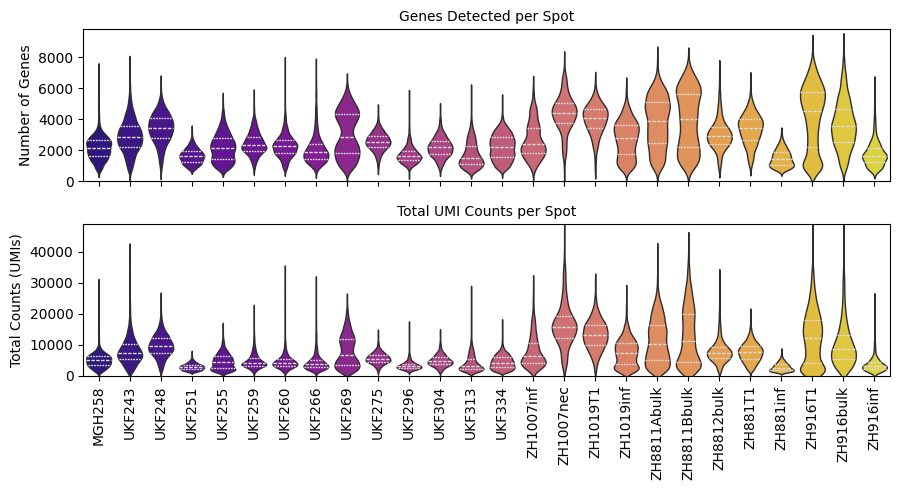

In [5]:
dpi = 300
fontsize = 8
figsize = 2.5

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(figsize*3.64, figsize*2), sharex=True)

sns.violinplot(
    data=df_all,
    x='sample',
    y='n_genes',
    ax=ax1,
    palette='plasma', 
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax1.set_title('Genes Detected per Spot', fontsize=10)
ax1.set_ylabel('Number of Genes')
# ax1.yaxis.grid(True)
ax1.set_ylim([0, 9800])


sns.violinplot(
    data=df_all,
    x='sample',
    y='total_counts',
    ax=ax2,
    palette='plasma',
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax2.set_title('Total UMI Counts per Spot', fontsize=10)
ax2.set_ylabel('Total Counts (UMIs)')
ax2.set_xlabel('')
ax2.tick_params(axis='x', rotation=90)
# ax2.yaxis.grid(True)
ax2.set_ylim([0, 9800*5])

plt.tight_layout()
plt.savefig('plots_manuscript/qc_ravi.pdf')
plt.show()

In [6]:
sample_means = df_all.groupby('sample').agg({
    'n_genes': 'mean',
    'total_counts': 'mean'
}).reset_index()
sample_means

,sample,n_genes,total_counts
0,MGH258,2161.623870,5082.713867
1,UKF243,2909.621938,8038.006836
2,UKF248,3403.499007,9723.460938
3,UKF251,1605.565094,2876.501465
4,UKF255,2158.939880,4589.810547
5,UKF259,2439.203151,4770.236328
6,UKF260,2264.979396,4485.280762
7,UKF266,2066.661744,4491.716797
8,UKF269,3056.236567,7941.763672
9,UKF275,2553.650470,5648.541016


In [7]:
filtered_samples = sample_means[
    (sample_means['n_genes'] > 2000) & 
    (sample_means['total_counts'] > 6000)
]['sample'].tolist()
filtered_samples

['UKF243',
 'UKF248',
 'UKF269',
 'ZH1007inf',
 'ZH1007nec',
 'ZH1019T1',
 'ZH1019inf',
 'ZH8811Abulk',
 'ZH8811Bbulk',
 'ZH8812bulk',
 'ZH881T1',
 'ZH916T1',
 'ZH916bulk']

## Infer TF Activity
### Loading the TF-gene prior

In [8]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ravi_processed/gbm_qc/{sample}.h5ad")
    adatas[sample] = stan.add_gene_tf_matrix(adatas[sample],
                                            min_cells_proportion = 0.1,
                                            min_tfs_per_gene= 10,
                                            min_genes_per_tf= 5,
                                            gene_tf_source="hTFtarget",
                                            tf_list="humantfs",
                                            source_dir="resources/")

In [9]:
df_size = []
for sample in sample_list:
    D = adatas[sample].varm['gene_tf']
    Y = adatas[sample].to_df()
    df_size.append([D.shape[1], Y.shape[1], Y.shape[0],
                   D.T.abs().sum().min(),
                   D.abs().sum().min(),
                   (Y>0).sum().min(),
                   (Y>0).T.sum().min()])

df_size = pd.DataFrame(df_size, index=sample_list,
                      columns = ['TFs', 'Genes', 'Cells',
                                 'TFs_per_Gene', 'Genes_per_TF',
                                 'Cells_per_Gene', 'Genes_per_Cell'])
df_size

,TFs,Genes,Cells,TFs_per_Gene,Genes_per_TF,Cells_per_Gene,Genes_per_Cell
MGH258,204,5714,2212,10.0,5.0,222,444
UKF243,221,7483,1796,10.0,5.0,180,463
UKF248,230,8134,3020,10.0,5.0,302,437
UKF251,219,4224,3180,10.0,5.0,318,460
UKF255,209,6022,1996,10.0,7.0,200,554
UKF259,227,6716,3554,10.0,5.0,356,548
UKF260,224,6341,2815,10.0,5.0,282,497
UKF266,215,5647,2776,10.0,5.0,278,450
UKF269,224,7780,2680,10.0,5.0,268,499
UKF275,228,6742,3725,10.0,5.0,373,560


### Computing the spatially dependent kernel

In [10]:
for sample in sample_list:
    stan.pixel_intensity(adatas[sample], windowsize=25)
    stan.make_kernel_from_pixel(adatas[sample], n=250, im_feats_weight=0.05)
    sc.pp.normalize_total(adatas[sample])
    adatas[sample].layers['scaled'] = np.sqrt(adatas[sample].to_df())

### Running STAN

In [11]:
df_corr = []
paras_dict_tfa = {}

for sample in sample_list:
    print(sample)
    stan.assign_folds(adatas[sample], n_folds=10, random_seed=0)
    stan_model = stan.Stan(adatas[sample], layer='scaled')
    stan_model.fit(n_steps=7, stages=1,
                  grid_search_params={'lam1':[1000],'lam2':[1e-3, 1e3]})
    paras_dict_tfa[sample] = stan_model.params

    cor = stan_model.evaluate(fold=-1)
    adatas[sample].obs['pred_cor_stan'] = cor
    adatas[sample].obsm['tfa_stan'] = pd.DataFrame(stan_model.W_concat.T, 
                                                    index=adatas[sample].obs_names, 
                                                    columns=adatas[sample].uns['tf_names'])
    
    Y = adatas[sample].varm['gene_tf'].dot(stan_model.W_concat)
    mse = mean_squared_error(Y, adatas[sample].to_df('scaled').T)
    df_corr.append([round(np.nanmean(cor), 4), mse])

df_corr = pd.DataFrame(df_corr, index=sample_list,columns = ['spot_corr', 'mse'])

MGH258
Time elapsed: 6.13 seconds
UKF243
Time elapsed: 5.21 seconds
UKF248
Time elapsed: 10.56 seconds
UKF251
Time elapsed: 8.19 seconds
UKF255
Time elapsed: 5.33 seconds
UKF259
Time elapsed: 12.73 seconds
UKF260
Time elapsed: 9.99 seconds
UKF266
Time elapsed: 8.68 seconds
UKF269
Time elapsed: 11.58 seconds
UKF275
Time elapsed: 16.18 seconds
UKF296
Time elapsed: 11.33 seconds
UKF304
Time elapsed: 5.06 seconds
UKF313
Time elapsed: 6.91 seconds
UKF334
Time elapsed: 9.07 seconds
ZH1007inf
Time elapsed: 4.05 seconds
ZH1007nec
Time elapsed: 3.12 seconds
ZH1019T1
Time elapsed: 3.58 seconds
ZH1019inf
Time elapsed: 4.64 seconds
ZH8811Abulk
Time elapsed: 8.18 seconds
ZH8811Bbulk
Time elapsed: 8.91 seconds
ZH8812bulk
Time elapsed: 6.02 seconds
ZH881T1
Time elapsed: 9.69 seconds
ZH881inf
Time elapsed: 2.36 seconds
ZH916T1
Time elapsed: 9.03 seconds
ZH916bulk
Time elapsed: 7.23 seconds
ZH916inf
Time elapsed: 2.19 seconds


In [12]:
paras_dict_tfa

{'MGH258': {'lam2': 1000.0, 'lam1': 1000},
 'UKF243': {'lam2': 1000.0, 'lam1': 1000},
 'UKF248': {'lam2': 0.01, 'lam1': 1000},
 'UKF251': {'lam2': 1000.0, 'lam1': 1000},
 'UKF255': {'lam2': 0.01, 'lam1': 1000},
 'UKF259': {'lam2': 0.01, 'lam1': 1000},
 'UKF260': {'lam2': 1000.0, 'lam1': 1000},
 'UKF266': {'lam2': 100.0, 'lam1': 1000},
 'UKF269': {'lam2': 1000.0, 'lam1': 1000},
 'UKF275': {'lam2': 100.0, 'lam1': 1000},
 'UKF296': {'lam2': 1000.0, 'lam1': 1000},
 'UKF304': {'lam2': 100.0, 'lam1': 1000},
 'UKF313': {'lam2': 1000.0, 'lam1': 1000},
 'UKF334': {'lam2': 1000.0, 'lam1': 1000},
 'ZH1007inf': {'lam2': 0.001, 'lam1': 1000},
 'ZH1007nec': {'lam2': 1.0, 'lam1': 1000},
 'ZH1019T1': {'lam2': 100.0, 'lam1': 1000},
 'ZH1019inf': {'lam2': 1000.0, 'lam1': 1000},
 'ZH8811Abulk': {'lam2': 1000.0, 'lam1': 1000},
 'ZH8811Bbulk': {'lam2': 1000.0, 'lam1': 1000},
 'ZH8812bulk': {'lam2': 100.0, 'lam1': 1000},
 'ZH881T1': {'lam2': 1000.0, 'lam1': 1000},
 'ZH881inf': {'lam2': 1000.0, 'lam1': 1000}

In [13]:
df_corr

,spot_corr,mse
MGH258,0.2830,0.496268
UKF243,0.2899,0.590771
UKF248,0.2436,0.713722
UKF251,0.2051,0.361846
UKF255,0.1903,0.435783
UKF259,0.1688,0.370313
UKF260,0.2487,0.374699
UKF266,0.3466,0.351023
UKF269,0.2784,0.502901
UKF275,0.2617,0.484280


In [14]:
path = 'results'
if not os.path.exists(path):
    os.mkdir(path)
    
path = 'results/ravi_tfa'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adatas[sample].write(f"{path}/{sample}.h5ad")

## Infer Pathway Activity
### Loading the pathway-gene prior

In [15]:
path2remove = ['HALLMARK_ADIPOGENESIS',
               'HALLMARK_MYOGENESIS',
               'HALLMARK_PANCREAS_BETA_CELLS',
               'HALLMARK_SPERMATOGENESIS',
               'HALLMARK_BILE_ACID_METABOLISM']

In [16]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ravi_processed/gbm_qc/{sample}.h5ad")
    adatas[sample] = stan.add_gene_pw_matrix(adatas[sample],
                                             min_cells_proportion = 0.1,
                                             path2remove = path2remove,
                                             source_dir="resources/")

In [17]:
df_size = []
for sample in sample_list:
    D = adatas[sample].varm['gene_pw']
    Y = adatas[sample].to_df()
    df_size.append([D.shape[1], Y.shape[1], Y.shape[0],
                   D.T.abs().sum().min(),
                   D.abs().sum().min(),
                   (Y>0).sum().min(),
                   (Y>0).T.sum().min()])

df_size = pd.DataFrame(df_size, index=sample_list,
                      columns = ['Pathways', 'Genes', 'Cells',
                                 'PWs_per_Gene', 'Genes_per_PW',
                                 'Cells_per_Gene', 'Genes_per_Cell'])
df_size

,Pathways,Genes,Cells,PWs_per_Gene,Genes_per_PW,Cells_per_Gene,Genes_per_Cell
MGH258,45,2072,2212,1.0,14.0,222,183
UKF243,45,2490,1796,1.0,19.0,180,208
UKF248,45,2684,3020,1.0,19.0,302,181
UKF251,45,1673,3180,1.0,10.0,318,195
UKF255,45,2116,1996,1.0,14.0,200,221
UKF259,45,2317,3554,1.0,17.0,356,243
UKF260,45,2221,2815,1.0,17.0,282,198
UKF266,45,2013,2776,1.0,13.0,278,187
UKF269,45,2588,2680,1.0,17.0,268,211
UKF275,45,2330,3725,1.0,18.0,373,229


### Computing the spatially dependent kernel

In [18]:
for sample in sample_list:
    stan.pixel_intensity(adatas[sample], windowsize=25)
    stan.make_kernel_from_pixel(adatas[sample], n=250, im_feats_weight=0.05)
    sc.pp.normalize_total(adatas[sample])
    adatas[sample].layers['scaled'] = np.sqrt(adatas[sample].to_df())

### Running STAN

In [19]:
df_corr = []
paras_dict_pwa = {}

for sample in sample_list:
    print(sample)
    stan.assign_folds(adatas[sample], n_folds=10, random_seed=0)
    stan_model = stan.Stan(adatas[sample], layer='scaled', prior='gene_pw')
    stan_model.fit(n_steps=7, stages=1,
                  grid_search_params={'lam1':[1000],'lam2':[1e-3, 1e3]})
    paras_dict_pwa[sample] = stan_model.params

    cor = stan_model.evaluate(fold=-1)
    adatas[sample].obs['pred_cor_stan'] = cor
    adatas[sample].obsm['pwa_stan'] = pd.DataFrame(stan_model.W_concat.T, 
                                                    index=adatas[sample].obs_names, 
                                                    columns=adatas[sample].uns['pw_names'])
    
    Y = adatas[sample].varm['gene_pw'].dot(stan_model.W_concat)
    mse = mean_squared_error(Y, adatas[sample].to_df('scaled').T)
    df_corr.append([round(np.nanmean(cor), 4), mse])
    
df_corr = pd.DataFrame(df_corr, index=sample_list, columns = ['spot_corr', 'mse'])

MGH258
Time elapsed: 3.86 seconds
UKF243
Time elapsed: 3.16 seconds
UKF248
Time elapsed: 5.80 seconds
UKF251
Time elapsed: 5.74 seconds
UKF255
Time elapsed: 3.59 seconds
UKF259
Time elapsed: 6.73 seconds
UKF260
Time elapsed: 5.08 seconds
UKF266
Time elapsed: 5.03 seconds
UKF269
Time elapsed: 4.96 seconds
UKF275
Time elapsed: 6.97 seconds
UKF296
Time elapsed: 7.49 seconds
UKF304
Time elapsed: 3.37 seconds
UKF313
Time elapsed: 4.84 seconds
UKF334
Time elapsed: 6.69 seconds
ZH1007inf
Time elapsed: 4.16 seconds
ZH1007nec
Time elapsed: 3.56 seconds
ZH1019T1
Time elapsed: 3.95 seconds
ZH1019inf
Time elapsed: 9.14 seconds
ZH8811Abulk
Time elapsed: 8.96 seconds
ZH8811Bbulk
Time elapsed: 8.25 seconds
ZH8812bulk
Time elapsed: 7.58 seconds
ZH881T1
Time elapsed: 14.00 seconds
ZH881inf
Time elapsed: 41.32 seconds
ZH916T1
Time elapsed: 66.95 seconds
ZH916bulk
Time elapsed: 58.16 seconds
ZH916inf
Time elapsed: 37.78 seconds


In [20]:
paras_dict_pwa

{'MGH258': {'lam2': 0.001, 'lam1': 1000},
 'UKF243': {'lam2': 0.001, 'lam1': 1000},
 'UKF248': {'lam2': 0.001, 'lam1': 1000},
 'UKF251': {'lam2': 0.001, 'lam1': 1000},
 'UKF255': {'lam2': 0.001, 'lam1': 1000},
 'UKF259': {'lam2': 0.001, 'lam1': 1000},
 'UKF260': {'lam2': 0.001, 'lam1': 1000},
 'UKF266': {'lam2': 0.001, 'lam1': 1000},
 'UKF269': {'lam2': 0.001, 'lam1': 1000},
 'UKF275': {'lam2': 0.001, 'lam1': 1000},
 'UKF296': {'lam2': 0.001, 'lam1': 1000},
 'UKF304': {'lam2': 0.001, 'lam1': 1000},
 'UKF313': {'lam2': 0.001, 'lam1': 1000},
 'UKF334': {'lam2': 0.001, 'lam1': 1000},
 'ZH1007inf': {'lam2': 0.001, 'lam1': 1000},
 'ZH1007nec': {'lam2': 0.1, 'lam1': 1000},
 'ZH1019T1': {'lam2': 1.0, 'lam1': 1000},
 'ZH1019inf': {'lam2': 0.001, 'lam1': 1000},
 'ZH8811Abulk': {'lam2': 0.001, 'lam1': 1000},
 'ZH8811Bbulk': {'lam2': 0.001, 'lam1': 1000},
 'ZH8812bulk': {'lam2': 0.01, 'lam1': 1000},
 'ZH881T1': {'lam2': 0.001, 'lam1': 1000},
 'ZH881inf': {'lam2': 0.001, 'lam1': 1000},
 'ZH916T1':

In [21]:
df_corr   

,spot_corr,mse
MGH258,0.1334,0.603309
UKF243,0.1394,0.813238
UKF248,0.1937,0.883845
UKF251,0.0801,0.442228
UKF255,0.1296,0.557222
UKF259,0.1202,0.481531
UKF260,0.1173,0.470269
UKF266,0.1161,0.407552
UKF269,0.1622,0.655377
UKF275,0.1208,0.601592


In [22]:
path = 'results/ravi_pwa'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adatas[sample].write(f"{path}/{sample}.h5ad")